# What grows in the closed box, layer by layer

This notebook takes **one run of the closed x-periodic box** (`examples/local_1d/run_periodic_1d.jl`) and shows,
with pictures, what the growing content is: where it sits in the water column, whether it oscillates or stands
still, where its energy is, and how it grows until the run breaks down.

Default case: **model 3, T = 1.6 s, 32 cells per wavelength, Crank–Nicolson** (`output/1D_stability_campaign/m3_q32_n32`),
which diverged at 246 s. Change `CASE` below to look at any other box run.

Everything used here is in the postprocessing package (`src/periodic.jl`, `src/periodic_plots.jl`; every function
has a docstring: `?plot_state`). The same figures for any run, from the command line:

    julia --project=postprocessing postprocessing/examples/periodic_viz.jl <run_dir> [--parts total,disturbance,16] [--dt 1] [--trange a b] [--phase 0]

Figures are saved in `<run>/viz/`.

## 1. What the data are

The solver writes a snapshot every 0.2 s (8 per wave period at T = 1.6 s). Each snapshot holds, along x:

* the free surface **η(x)**;
* the **layer velocities u₁(x), u₂(x), u₃(x)**. For P1LFE-2 the water column σ ∈ [0, 1] has three vertical nodes,
  σ = 0 (bed), 0.728 and 1 (surface). u_j is the horizontal velocity **at node j**.

Between the nodes the velocity is a straight line (the hat functions φ_j):

  u(x, σ) = u₁(x) φ₁(σ) + u₂(x) φ₂(σ) + u₃(x) φ₃(σ).

The **depth-averaged velocity** is ū = Σ_j D_j u_j, with D = [0.364, 0.5, 0.136] (the area under each hat).
ū is what moves water from one place to another, so it is what raises or lowers η (mass conservation:
∂η/∂t = −∂(H ū)/∂x).

So there are two different kinds of velocity pattern:

* **ū ≠ 0**: the column moves as a whole. It changes η, so it is a *surface wave*. The carrier is like this.
* **ū = 0 but u_j ≠ 0**: the top of the column moves one way and the lower part the other way, so the net flow is
  zero. Nothing piles up, η does not move. This is a **vertical shear** pattern: invisible at the surface.

## 2. How we separate the wave from the disturbance

The box is exactly one carrier wavelength long, and periodic. Any field along x can be written as a sum of
**box harmonics** n = 1, 2, 3, …: harmonic n has n wavelengths in the box (wavelength L/n).

* n = 1 is the **carrier** wave.
* n = 2, 3, 4 are its **bound harmonics**: the steep wave is not a pure sine, and they ride along with it.
* **n ≥ 5 is called "the disturbance" here.** At t = 0 it is a tiny seed, 10⁻⁸, on every harmonic. In an exact
  solution of this wave it would stay tiny forever. Whatever grows there is the instability.

Every plotting function takes a **`part`** of the solution: `:total`, `:carrier` (n ≤ 4), `:disturbance` (n ≥ 5),
`:steady` (the disturbance averaged over one wave period: what does not oscillate), `:oscillating` (the rest), or a
list of harmonics such as `[16]` or `5:20`.

In [1]:
import Pkg
const ROOT = normpath(joinpath(pwd(), "..", ".."))      # the GridapBALFEM.jl repository
isfile(joinpath(ROOT, "postprocessing", "Project.toml")) || error("run this notebook from postprocessing/notebooks/")
Pkg.activate(joinpath(ROOT, "postprocessing"); io = devnull)
include(joinpath(ROOT, "postprocessing", "src", "GridapBALFEMPost.jl"))
using .GridapBALFEMPost, Plots, Printf
gr(fmt = :png, dpi = 100)
showpng(p) = (display(MIME("image/png"), p); nothing)   # one PNG per figure in the notebook (not PNG + SVG + HTML)

showpng (generic function with 1 method)

### Parameters

`CASE` is the run directory. The time windows and harmonics are chosen from the data in the next cells, but can be
overridden.

In [2]:
CASE   = joinpath(ROOT, "output", "1D_stability_campaign", "m3_q32_n32")
NMIN   = 5                        # harmonics n ≥ NMIN are "the disturbance"
OUTDIR = mkpath(joinpath(CASE, "viz"))

R = load_periodic(CASE)           # reads every VTK once (a few seconds), then a cache
m = R.meta
println(R)
println("A = ", m.A, " m, regime ", m.regime, ", nl_pressure ", m.nl_pressure, ", CIP γ_u ", m.cip_gamma_u,
        ", Q", m.p_u, "/Q", m.p_eta, ";  D = ", round.(R.D; digits = 4))

PeriodicRun(m3_q32_n32: T=1.60 s, d=3.50 m, 32 cells, Nσ=3, 1231 snapshots 0.2–246.2 s)


A = 0.1 m, regime :nonlinear, nl_pressure false, CIP γ_u 0.0, Q3/Q2;  D = 

[0.364, 0.5, 0.136]


## 3. Which harmonics grow, and what kind are they?

The table fits each harmonic of the **surface-layer velocity** over a time window and lists the fastest growing ones
(then the same table sorted by size). The columns:

* **σ**: growth rate, |û| ∝ e^{σt}. σ = 0.07 /s means ×2 every 10 s.
* **ω/ω0**: how fast it oscillates in time, in units of the carrier frequency ω0 = 2π/T.
  **0 means it does not oscillate at all: a pattern that stands still and only grows.**
  ±2 means twice the wave frequency; the sign is the direction it travels (+ = with the carrier).
* **|u|/|ū|**: surface-layer velocity over depth-averaged velocity. For the carrier it is ≈ 5 (the wave is
  stronger near the surface). **Very large = vertical shear with almost no net flow.**
* **η√(g/d)/|u|**: how much it lifts the free surface, in velocity units. ≈ 0 = invisible at the surface.

The window ends where the disturbance reaches 2 % of the carrier: up to there it is a clean exponential growth;
after it the run is in its final break-down.

In [3]:
T_LIN = end_of_linear_growth(R; nmin = NMIN)
TW    = (max(R.t[1], T_LIN - 60), T_LIN)
rows  = growing_harmonics(R; tw = TW, top = 12)
growing_harmonics(R; tw = TW, top = 6, sortby = :amp)
TRIAD = pick_triad(rows; nmin = NMIN)
HARM  = isnothing(TRIAD) ? [1, 2, rows[1].n, m.ncell] : [1, 2, TRIAD[1], TRIAD[2], m.ncell]
LABEL = isnothing(TRIAD) ? ["carrier", "carrier's 2nd harmonic", "fastest growing", "1 wavelength per cell"] :
        ["carrier", "pump: carrier's 2nd harmonic", "steady member", "fast member", "1 wavelength per cell"]
T_SHOW = T_LIN - 5                # the instant used by the snapshot figures
println("\nend of the clean growth: t = ", T_LIN, " s;  harmonics shown below: ", HARM, ";  triad guess ", TRIAD)

Fastest-growing harmonics of u3, t ∈ [131.2, 191.2] s:
     n     σ (1/s)      ω/ω0       |u|/|ū|   η√(g/d)/|u|  |û| at end


    14     +0.0753    -1.680          10.2          1.68     7.4e-04
    16     +0.0746    +0.010         160.1          0.17     2.2e-03
    13     +0.0745    -1.978           9.6          1.63     8.4e-04
    15     +0.0740    +0.007          60.9          0.31     1.7e-03
    18     +0.0733    +1.992           9.4          2.47     5.1e-04
    12     +0.0710    -1.982           8.5          1.41     3.3e-04
    75     +0.0691    -1.254           5.9          4.57     7.5e-07
    11     +0.0690    -1.805           8.4          1.28     9.5e-05
    86     +0.0683    -0.339           5.8          3.92     2.5e-07
    85     +0.0682    +1.071           5.7          4.82     8.4e-07
    43     +0.0682    -1.836           6.4          3.76     1.5e-06
    74     +0.0680    -0.479           5.9          3.63     2.7e-07


Fastest-growing harmonics of u3, t ∈ [131.2, 191.2] s:
     n     σ (1/s)      ω/ω0       |u|/|ū|   η√(g/d)/|u|  |û| at end
     2     -0.0001    +1.379           7.1          0.52     1.0e-02
    16     +0.0746    +0.010         160.1          0.17     2.2e-03
    15     +0.0740    +0.007          60.9          0.31     1.7e-03
    13     +0.0745    -1.978           9.6          1.63     8.4e-04
    14     +0.0753    -1.680          10.2          1.68     7.4e-04
    17     +0.0672    +0.012          21.5          1.06     6.3e-04

end of the clean growth: t = 191.2 s;  harmonics shown below: 

[1, 2, 16, 14, 32];  triad guess (16, 14)


In the default case the two fastest are **n = 14 and n = 16, growing at the same rate (0.075 /s)**, and they are of
two different kinds:

* **n = 16 (and 15): ω ≈ 0, |u|/|ū| ≈ 160, η ≈ 0.** A pattern that stands still, with the layers pushing in
  opposite directions so that the net flow is zero. This is the **"steady vertical shear mode"**.
* **n = 14 (and 13, 12): ω ≈ −2ω0, |u|/|ū| ≈ 10, η clearly present.** An ordinary short surface wave, travelling
  *against* the carrier, at twice its frequency.

The triad guess (`pick_triad`) takes the largest steady growing harmonic as the steady member and n − 2 as the fast
one; confirm it in the table (equal σ, ω ≈ 0 and ≈ ±2) before relying on it.

## 4. Everything at one instant

`plot_state` shows all fields at one time: the free surface, every layer velocity with the depth average, the
velocity inside the water column with streamlines and, on the right, the **energy per mode** at that instant
(averaged over one wave period centred on t).

**Which modes exist.** It takes two points to describe one wavelength, so N independent values along x
hold the modes n = 0 … N/2. The velocity is cubic (Q3): 3 nodes per cell, 32 × 3 = 96 values per layer,
**modes n ≤ 48**. The surface is quadratic (Q2): 2 nodes per cell, 64 values, **modes n ≤ 32**.
(The snapshots hold 6 samples per cell, so an FFT of them reaches n = 95, but everything above the node
limit only repeats the modes below it, as images at 32q ± n. The panels therefore use the **nodal values**,
where each mode appears exactly once with all its energy.)

**Reading the panels** (`state_spectrum`):
* beside η: the **surface energy ½gη² per η mode**, n ≤ 32;
* beside the water column: the **kinetic energy per velocity mode**, n ≤ 48, split into depth-mean flow (blue),
  vertical shear (orange) and the vertical velocity w (green); the thick grey line is their sum. n = 32
  (purple dotted) is one wavelength per cell; the red star at n = 0 is the x-uniform flow;
* in both, the dashed grey line is the same at t = 0 (the seed level), and the band of the part shown on the
  left is shaded yellow;
* the totals (beside the layer velocities): E/E0 with the w energy (which the solver's monitor leaves out),
  the surface share, the x-uniform flow, and the share of the disturbance (n ≥ 5) with its dominant kind.

First the **total** solution: the carrier wave, strongest at the surface, the whole column moving the same way
under each crest and trough.

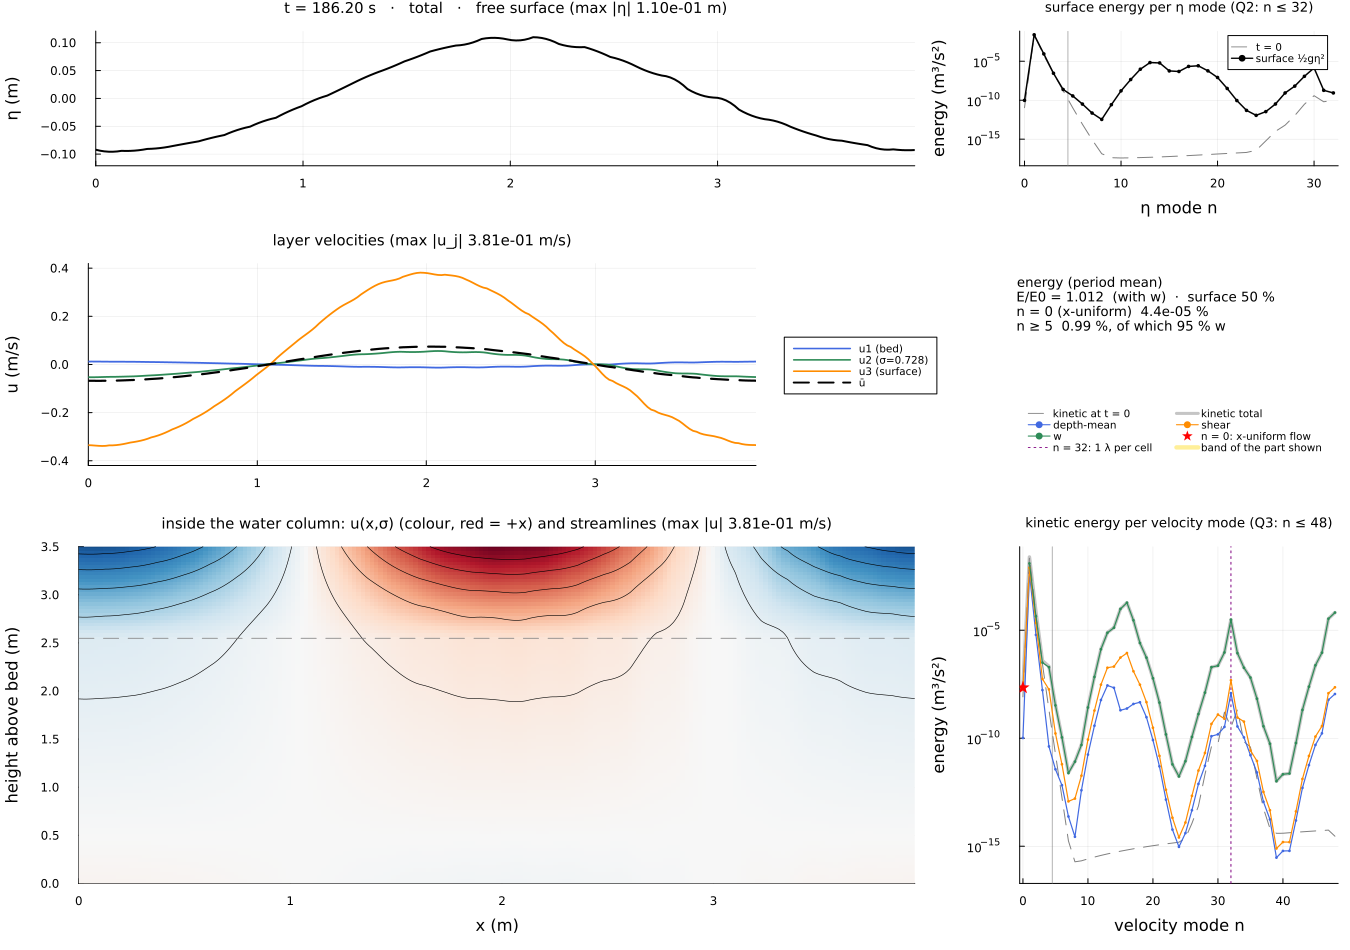

In [4]:
f = plot_state(R, T_SHOW; part = :total); savefig(f, joinpath(OUTDIR, "s_state_total.png")); showpng(f)

The same instant, **disturbance only** (n ≥ 5; every panel divided by its own maximum, printed in the titles).
Compare the layer panel with the total above: here the layers move **against each other** and ū (black dashed) stays
near zero; in the water column the streamlines close into **cells**.

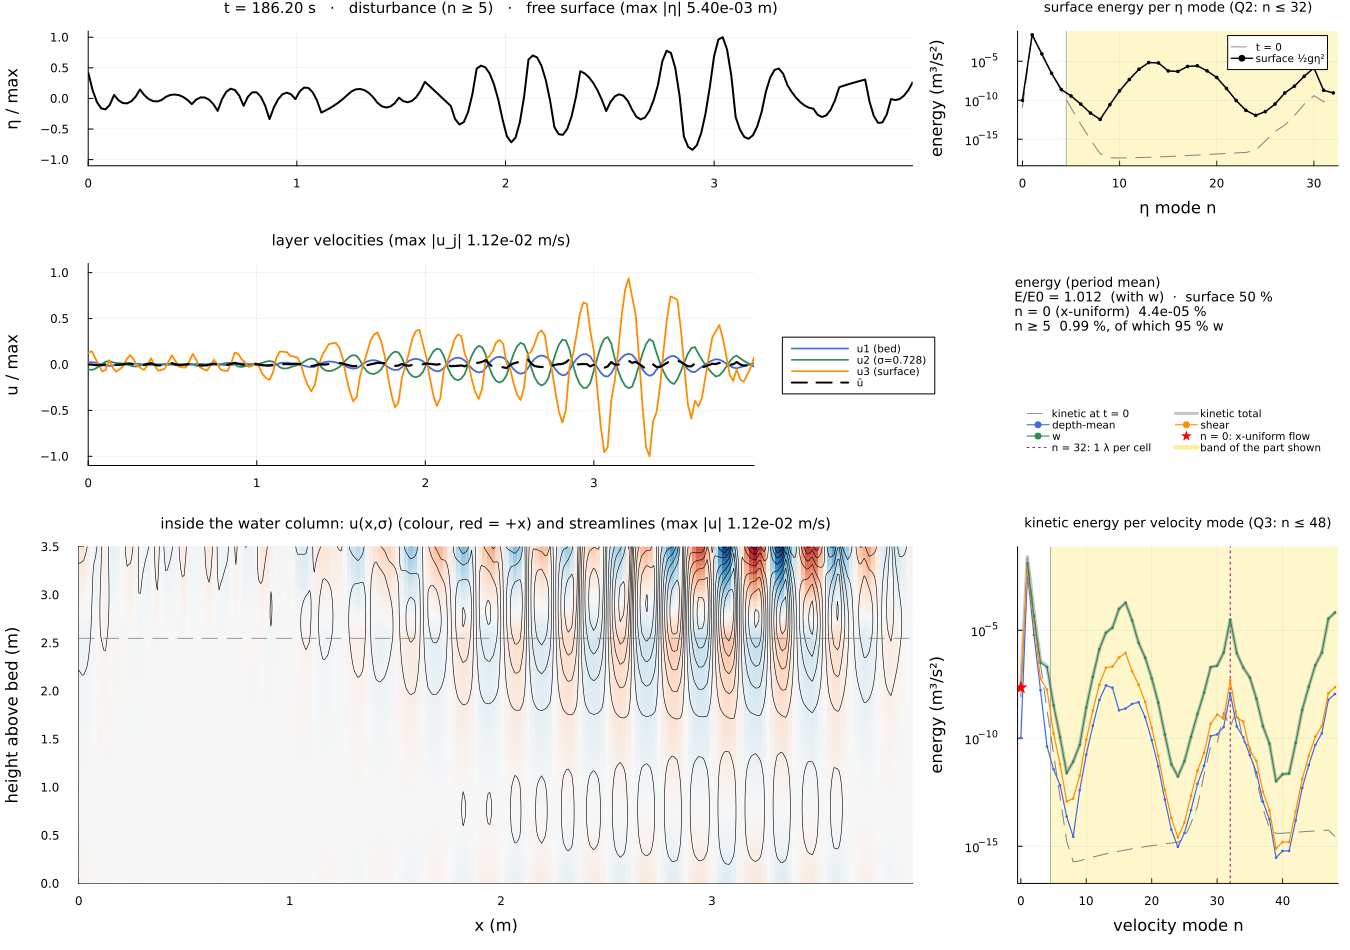

In [5]:
f = plot_state(R, T_SHOW; part = :disturbance); savefig(f, joinpath(OUTDIR, "s_state_disturbance.png")); showpng(f)

And **one harmonic alone**, the steady member: a perfectly regular row of overturning cells.

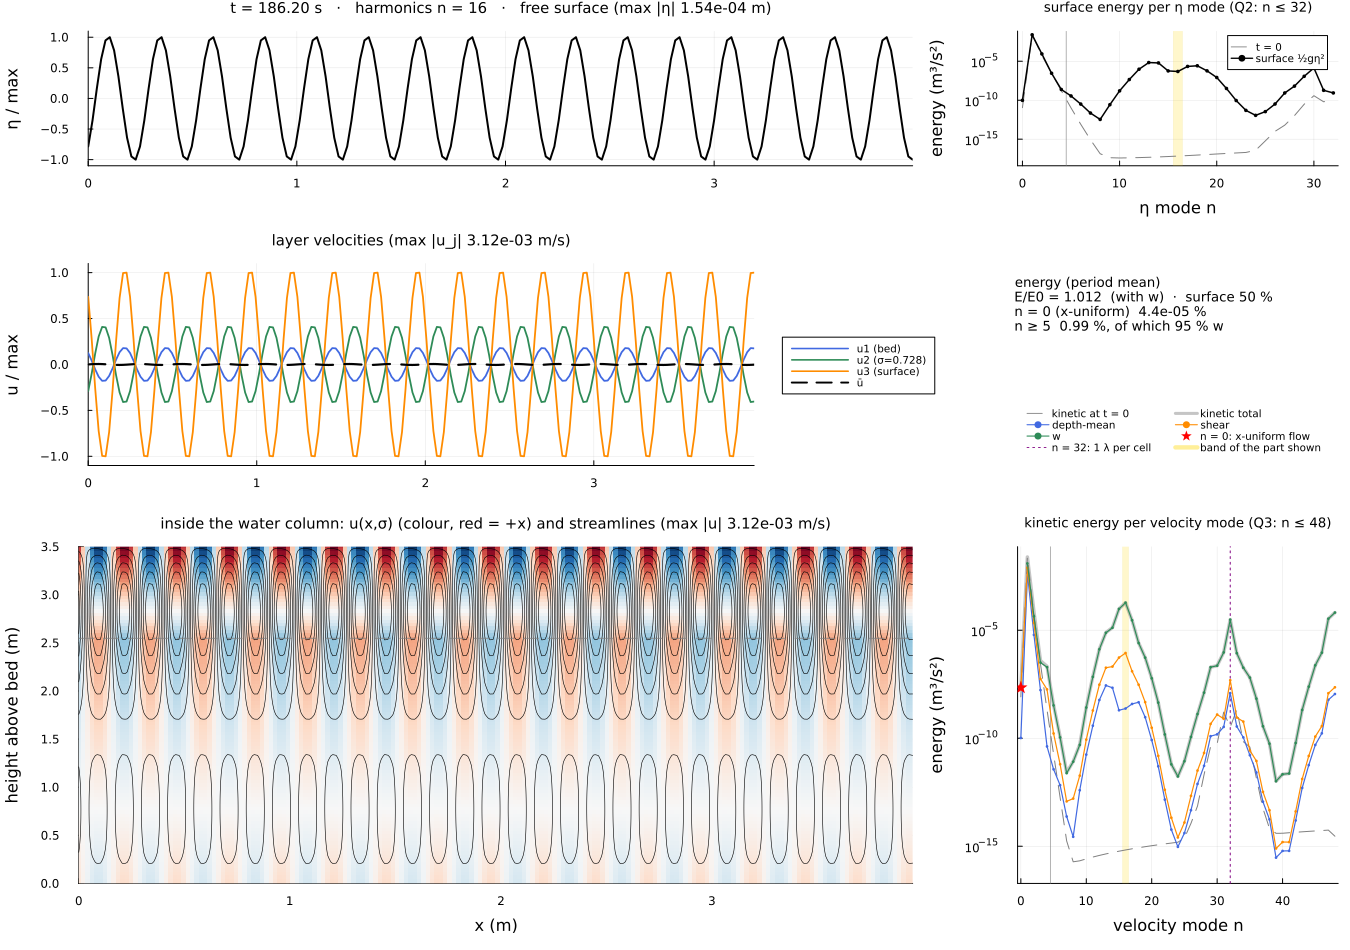

In [6]:
f = plot_state(R, T_SHOW; part = [HARM[3]]); savefig(f, joinpath(OUTDIR, "s_state_n$(HARM[3]).png")); showpng(f)

### A merged view: the layer velocities drawn inside the water column

`plot_state_wiggle` (in the package, `src/periodic_plots.jl`) joins the layer-velocity panel and the water-column panel of `plot_state` into one:

* **left axis: σ** (0 = bed, 1 = surface); the background is u(x, σ) (colour, red = +x) with the streamlines;
* each layer velocity **u_j(x) is drawn on its own node**, as the curve σ_j + s·u_j(x) (black, white halo),
  around a dotted baseline at σ_j where u_j = 0. All layers share **one scale s**: the largest |u_j| fills a fraction
  `amp` (default 0.45) of the smallest gap between nodes;
* **right axis: u_j in m/s** (or u/max for the disturbance parts), read about each baseline: every node carries
  its own 0 and ±U ticks;
* on the right, the same two energy panels as in `plot_state`, each on the row of its field.

The curves of the bed (σ = 0) and surface (σ = 1) nodes swing outside [0, 1], into the white margins. With the
total field the bed curve is nearly flat: u₁ is about 25× smaller than u₃.

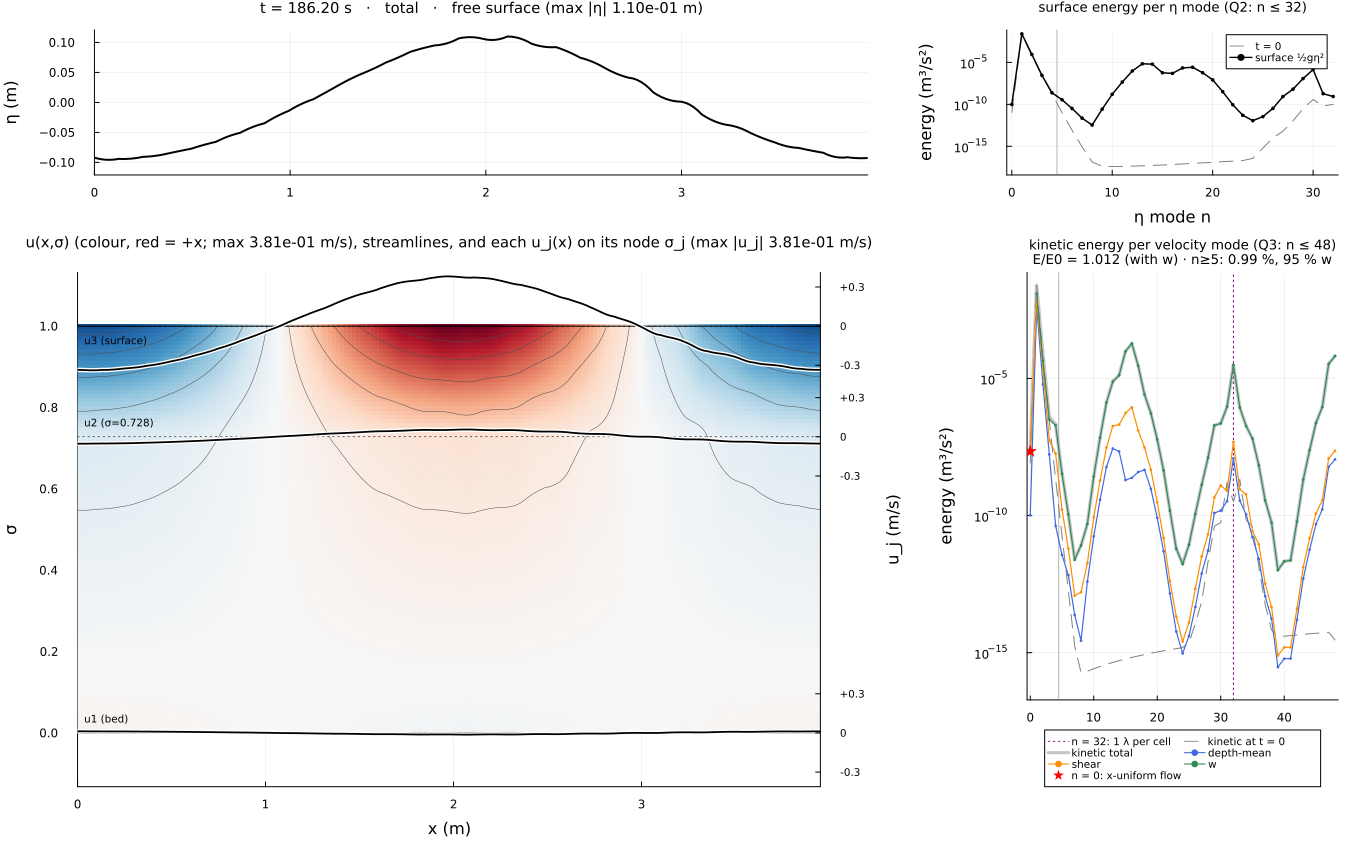

In [7]:
f = plot_state_wiggle(R, T_SHOW; part = :total); savefig(f, joinpath(OUTDIR, "s_state_wiggle_total.png")); showpng(f)

The disturbance at the same instant: the surface curve and the colour just below it agree (red where u₃ > 0), the middle node swings the opposite way, and the cells sit in the upper part of the column.

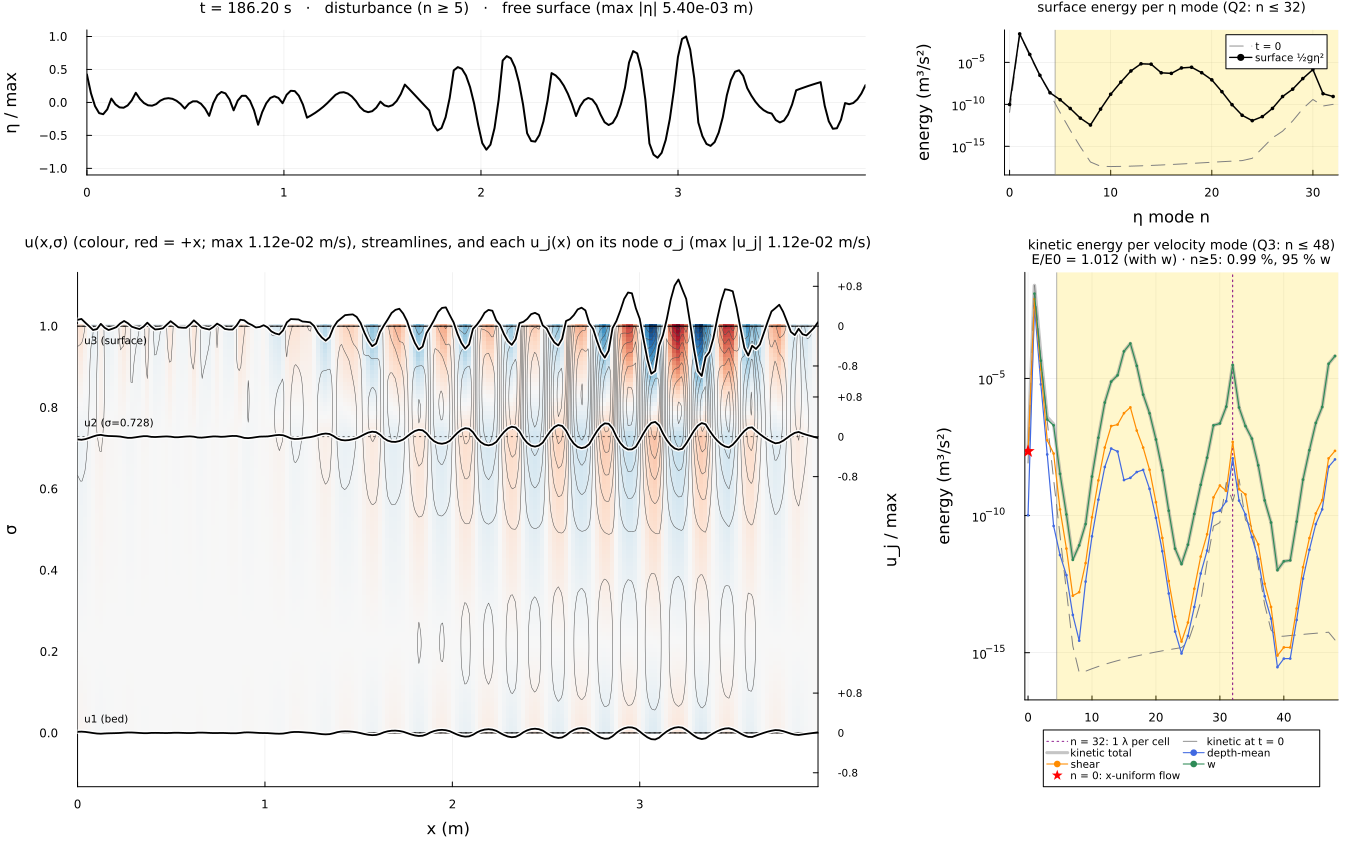

In [8]:
f = plot_state_wiggle(R, T_SHOW; part = :disturbance); savefig(f, joinpath(OUTDIR, "s_state_wiggle_disturbance.png")); showpng(f)

## 5. Time marching

`animate_run` makes one `plot_state` per frame and writes a video. **Frame selection** (`select_frames`):

* `select_frames(R; dt = 1.0)`: one frame per second of simulated time;
* `select_frames(R; trange = (150, 200), every = 1)`: every snapshot in a window (0.2 s apart: the waves move);
* `select_frames(R; n = 60)`: 60 frames evenly over the run;
* `select_frames(R; times = [50, 100, 150])`: chosen instants;
* `select_frames(R; trange = (100, 246), phase = 0.0)`: **stroboscopic**, one frame per wave period at the same
  phase: the carrier looks frozen, so only what does not move with the wave changes between frames.

For `:total` and `:carrier` the axes are fixed over the frames (you see the size change); for the disturbance parts
every frame is normalised (you see the shape; the size is in the titles and in the growth strip at the bottom).
A static alternative: a few chosen instants side by side.

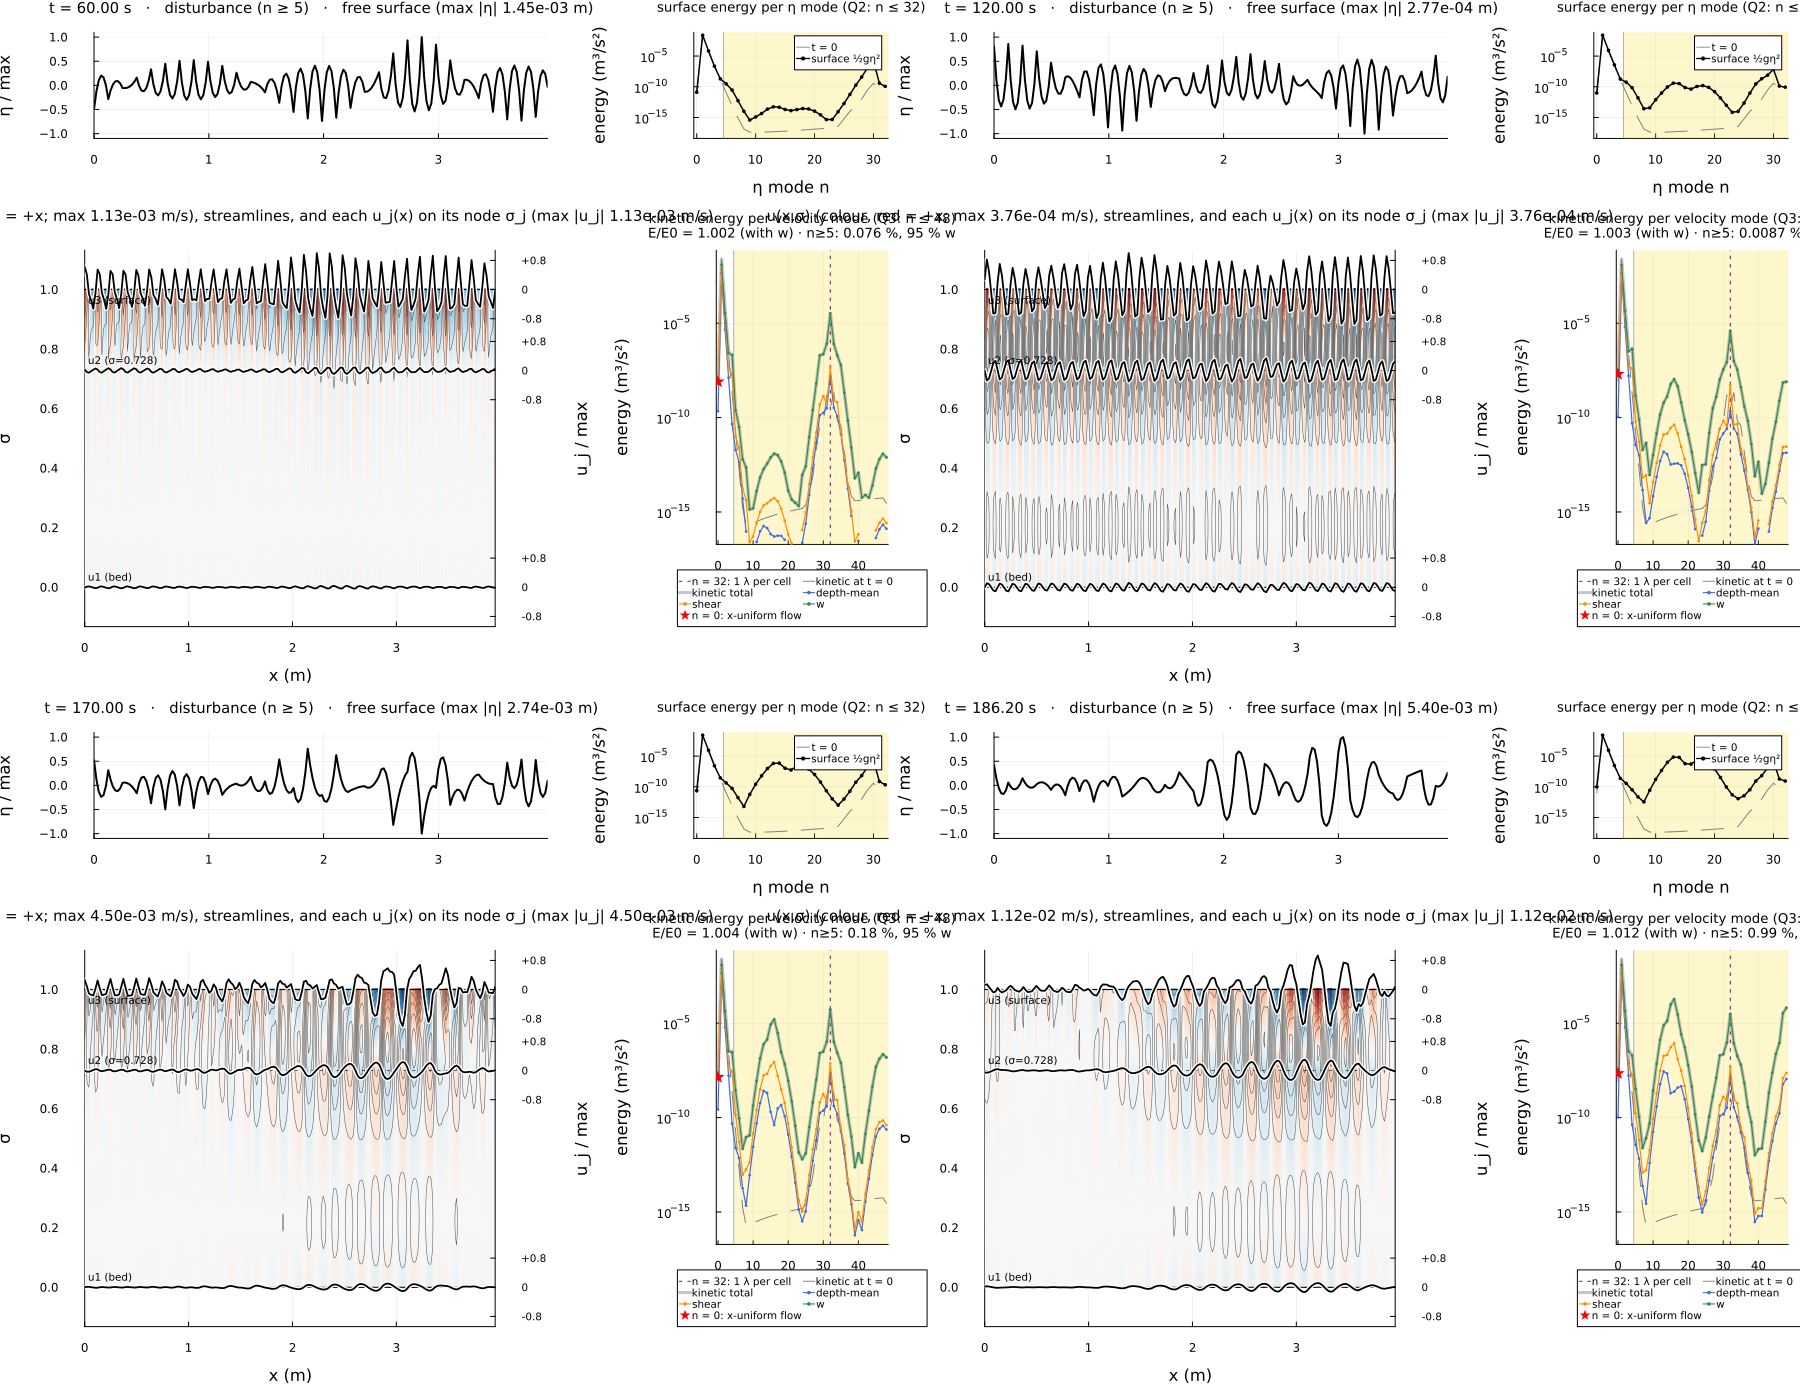

In [9]:
fr = select_frames(R; times = [60, 120, 170, T_SHOW])
showpng(plot([plot_state_wiggle(R, it; part = :disturbance, size = (900, 700)) for it in fr]...; layout = (2, 2), size = (1800, 1400)))

In [10]:
# videos (≈ 1–2 min each); they are written next to the figures
v1 = animate_run(R; frames = select_frames(R; dt = 1.0), part = :total, out = joinpath(OUTDIR, "state_total.mp4"))
v2 = animate_run(R; frames = select_frames(R; dt = 1.0), part = :disturbance, out = joinpath(OUTDIR, "state_disturbance.mp4"))
v3 = animate_run(R; frames = select_frames(R; trange = (T_LIN - 40, T_LIN + 30), phase = 0.0), part = :steady,
                 fps = 6, out = joinpath(OUTDIR, "state_steady_strobe.mp4"))
v4 = animate_mode(R, HARM[4]; frames = select_frames(R; trange = (T_LIN - 4m.T, T_LIN)), fps = 8,
                  out = joinpath(OUTDIR, "state_n$(HARM[4]).mp4"))
println.((v1, v2, v3, v4));

[ Info: Saved animation to /home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_total.mp4


[ Info: Saved animation to /home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_disturbance.mp4


[ Info: Saved animation to /home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_steady_strobe.mp4


/home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_total.mp4
/home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_disturbance.mp4
/home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_steady_strobe.mp4
/home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_n14.mp4


[ Info: Saved animation to /home/pmanyerfuertes/Documents/TU-Delft/WP2/BALFEM_model/GridapBALFEM.jl/output/1D_stability_campaign/m3_q32_n32/viz/state_n14.mp4


## 6. How big is the disturbance, layer by layer?

Root-mean-square over the box of the disturbance (all n ≥ 5), per layer, against time, on a log scale.

* The first ~100 s are an **initial adjustment**: the starting wave is not exactly the model's nonlinear wave, so
  the start excites many harmonics; most of them do not grow.
* After that, a **straight line on a log scale = exponential growth**: that is the instability.
* Compare the coloured lines (the layers) with the **thick black line (ū)**: the layers carry far more than their
  average. The growth is in the vertical structure, not in the net flow.

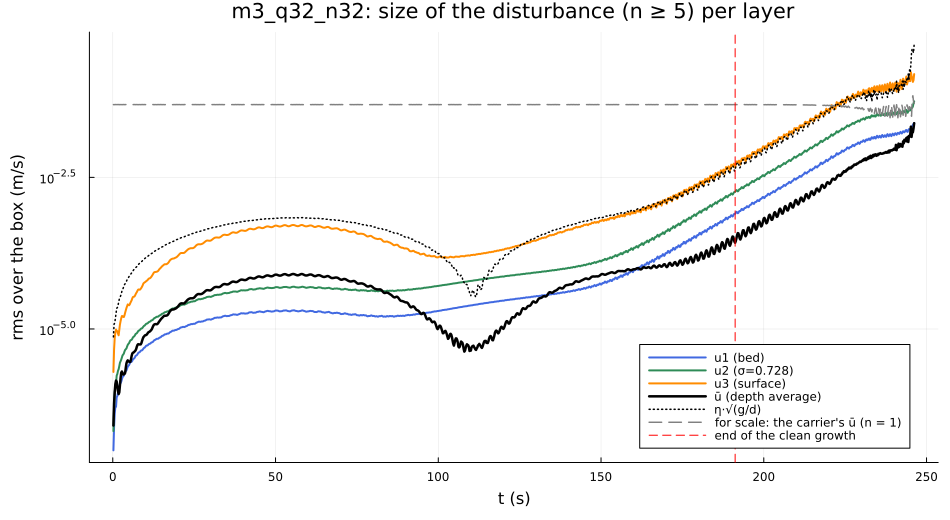

In [11]:
f = plot_growth_overview(R; nmin = NMIN); vline!(f, [T_LIN]; c = :red, ls = :dash, label = "end of the clean growth")
savefig(f, joinpath(OUTDIR, "01_growth_overview.png")); showpng(f)

## 7. Each harmonic separately

**Amplitude per layer over the whole run.** The steady member: all three layers grow along straight parallel lines
from the very start, while ū (black) stays about 100 times below them. The fast member grows at the same rate, and its
ū and η are not small: it is a surface wave. The grid-scale harmonic (one wavelength per cell) only takes off near the
end, once the others are large: it is a consequence, not the cause.

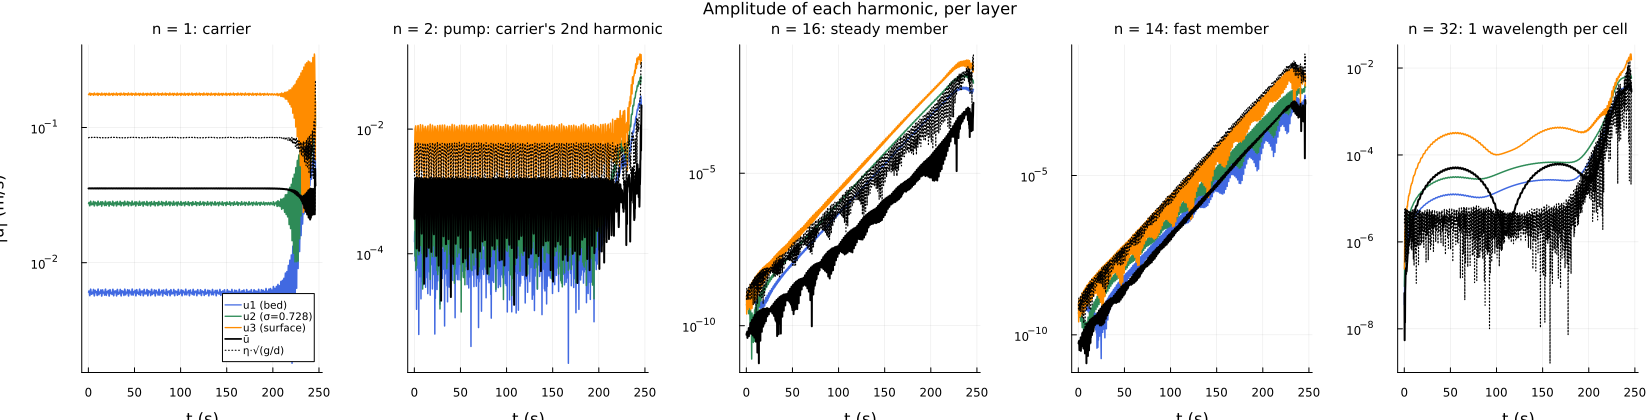

In [12]:
f = plot_mode_amplitudes(R, HARM; labels = LABEL); savefig(f, joinpath(OUTDIR, "04_mode_amplitudes.png")); showpng(f)

**Over a few wave periods**, seen at x = 0, one line per layer (grey lines one period apart):

* **carrier**: oscillates once per period, all layers in phase, the surface layer largest;
* **fast member**: oscillates **twice per period**, mostly in the surface layer;
* **steady member**: **does not oscillate at all.** Flat lines that only creep upwards (the growth), with the
  layers at **opposite signs** and ū (black dashed) on zero.

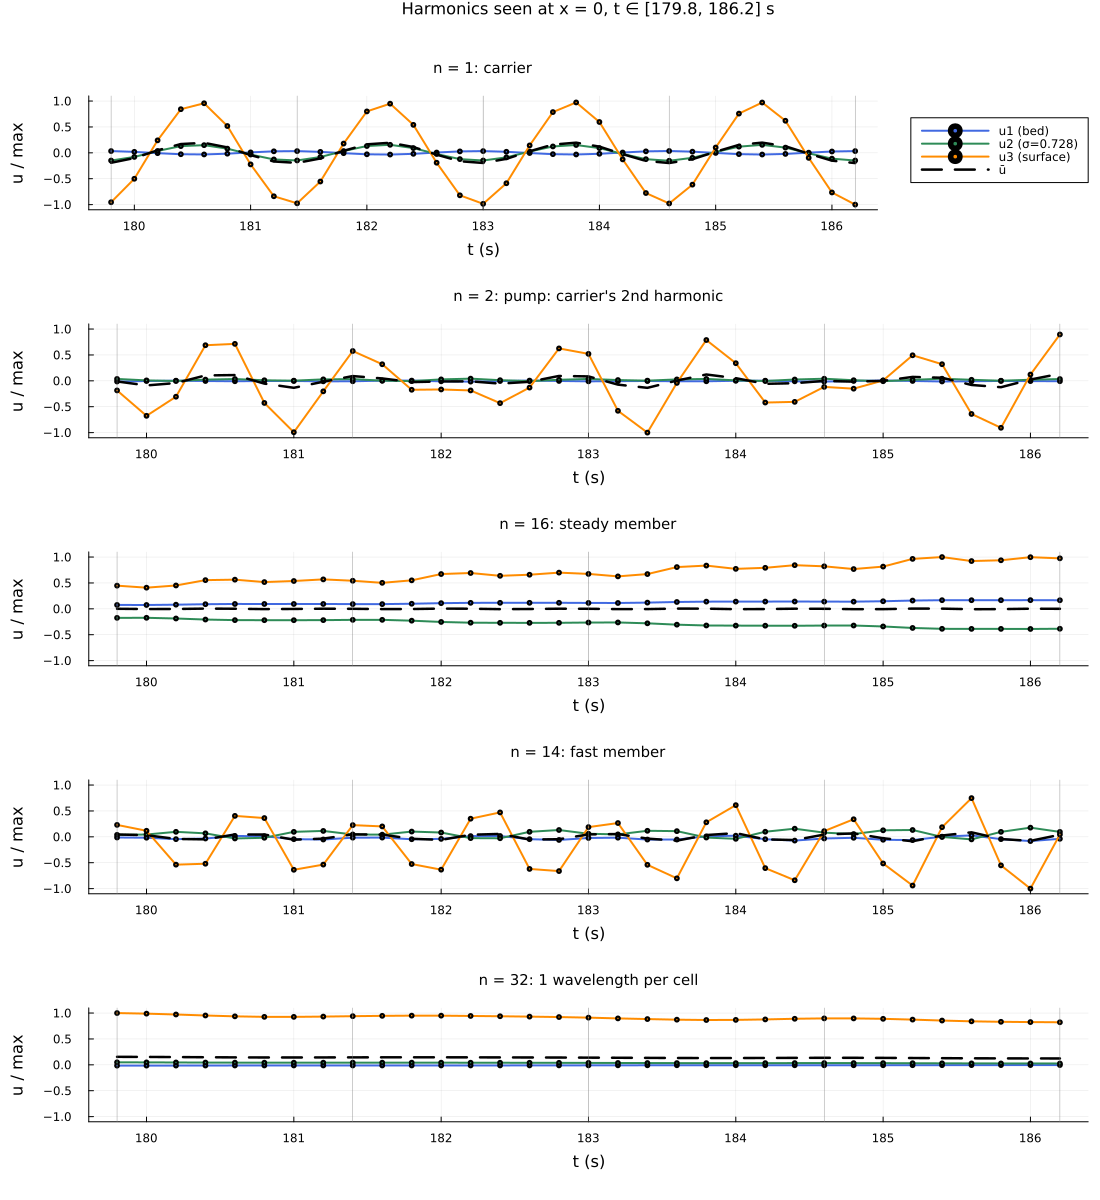

In [13]:
f = plot_mode_timeseries(R, HARM; tw = (T_SHOW - 4m.T, T_SHOW), labels = LABEL)
savefig(f, joinpath(OUTDIR, "05_mode_timeseries.png")); showpng(f)

**Phasors**: the complex amplitude of each layer in the plane, divided by the surface layer's size at each instant (so
the growth is removed and only the phase remains), over two wave periods. A wave goes **round the circle** (once per
period for the carrier, twice for the fast member). The steady member **sits still**: its layers are fixed points, on
opposite sides of 0 (they push against each other).

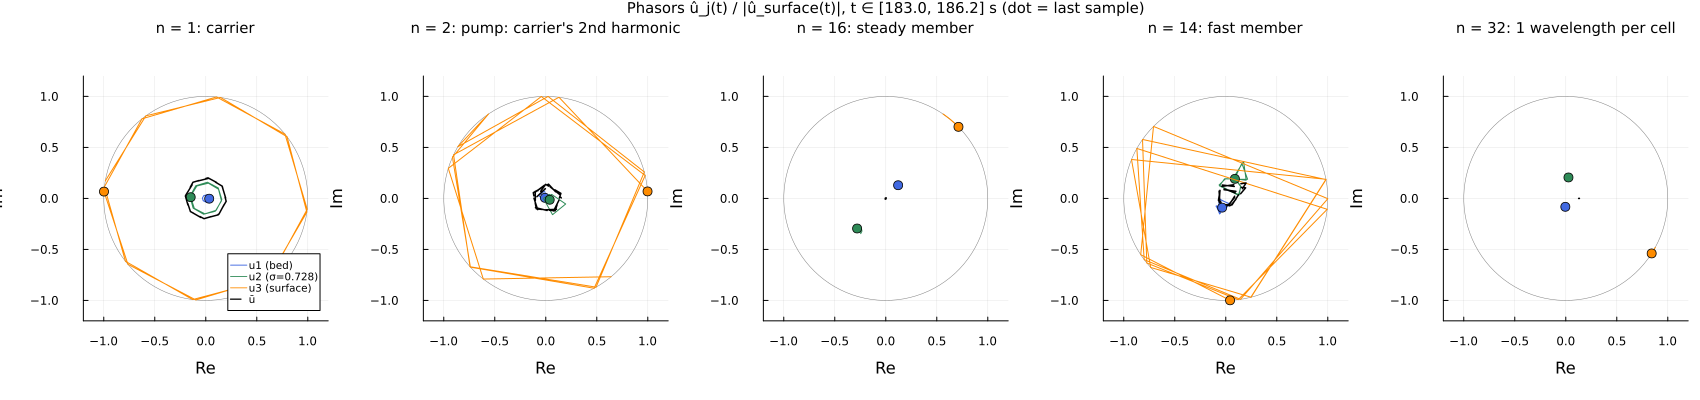

In [14]:
f = plot_mode_phasors(R, HARM; tw = (T_SHOW - 2m.T, T_SHOW), labels = LABEL)
savefig(f, joinpath(OUTDIR, "06_mode_phasors.png")); showpng(f)

**The profile through one wave period**: the vertical profile of a harmonic at every snapshot of one period, coloured
from dark (early) to light (late). The steady member draws **the same curve every time** (changing sign with depth);
the fast member **swings through ±**.

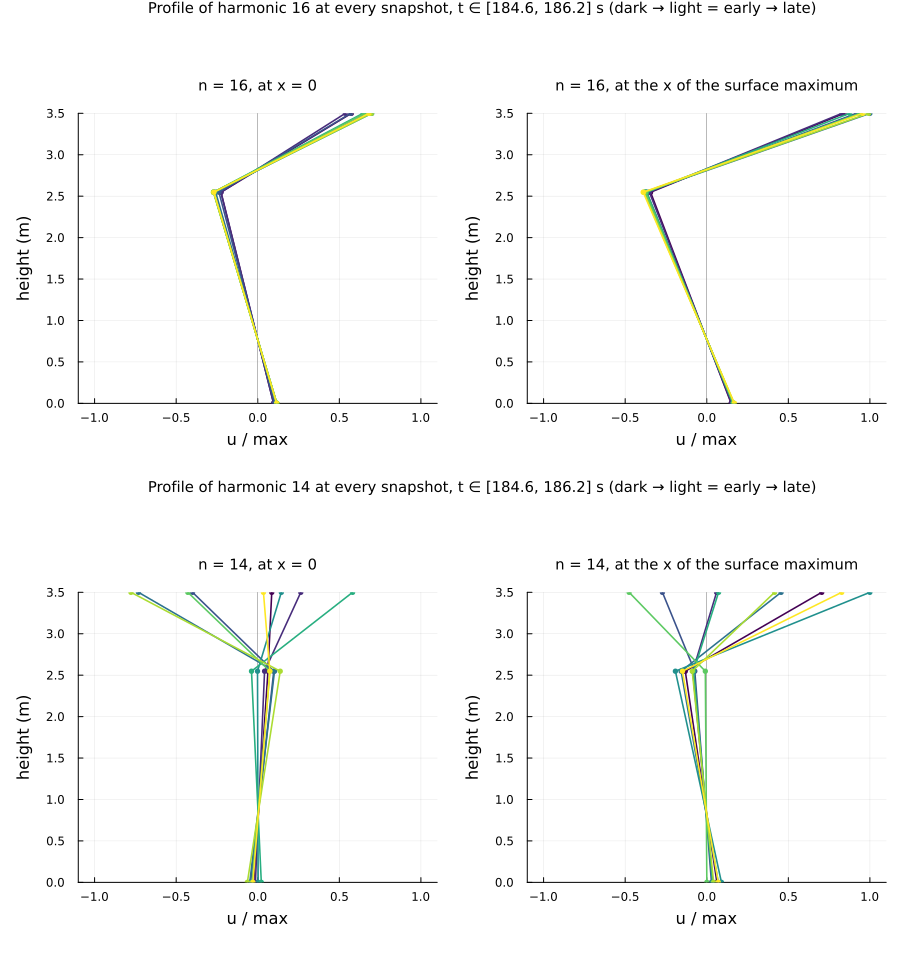

In [15]:
showpng(plot(plot_mode_cycle(R, HARM[3]; t0 = T_SHOW - m.T), plot_mode_cycle(R, HARM[4]; t0 = T_SHOW - m.T); layout = (2, 1), size = (900, 960)))

**Vertical profile of each harmonic** where it is largest. The carrier's whole column moves one way (ū clearly ≠ 0);
the steady member's profile changes sign and its depth average (red) sits on zero: the flow near the surface is
cancelled by the flow lower down.

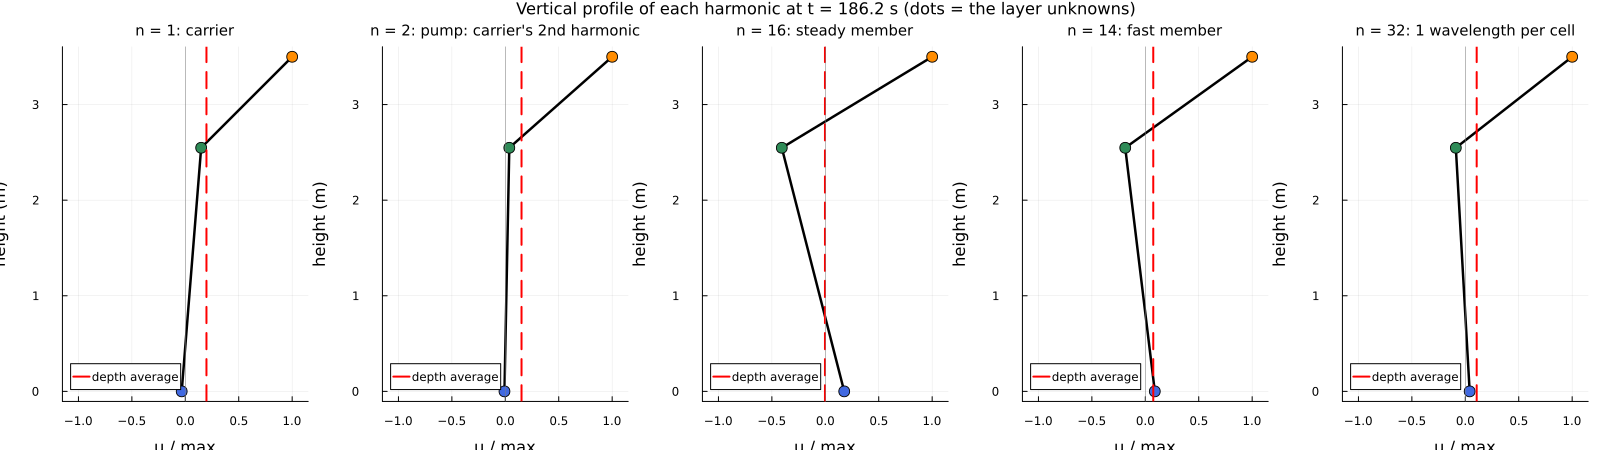

In [16]:
f = plot_mode_profiles(R, T_SHOW, HARM; labels = LABEL); savefig(f, joinpath(OUTDIR, "08_mode_profiles.png")); showpng(f)

## 8. Inside the water column: steady cells and moving waves

Colour: horizontal velocity u(x, σ) (red = towards +x). Black lines: **streamlines** of (u, w), from the stream
function ψ = d Σ_j u_j Φ_j(σ) (w from mass conservation, linearised, flat bed; only for drawing).

* Left, the **carrier** over the whole box: streamlines reach the surface, because the column moves as a whole.
* Middle, the **steady part of the disturbance**, zoomed in: a row of **closed overturning cells (rolls)**. Water goes
  one way near the surface and comes back lower down; the cells do not reach through the surface, so η does not move,
  and they do not move or oscillate: they only get stronger.
* Right, the **oscillating part**: short waves, strongest near the surface, moving.

Real water that starts without vorticity cannot spin up such rolls on its own (Kelvin's theorem). The layered model
does not impose that, which is why we suspect this mode is an artefact of the depth-integrated model.

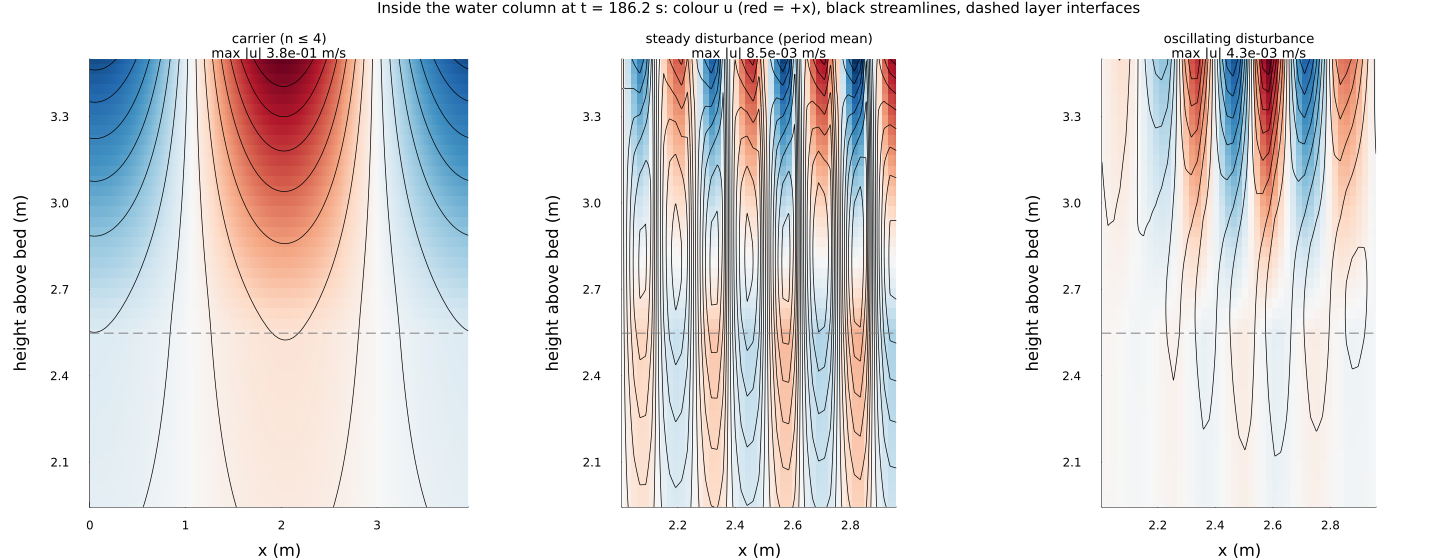

In [17]:
f = plot_column(R, T_SHOW; xw = (m.Lx / 2, 3m.Lx / 4), zw = (0.55m.d, m.d), nmin = NMIN)
savefig(f, joinpath(OUTDIR, "11_column.png")); showpng(f)

## 9. In space and time at once

Space–time maps (x horizontal, time upwards). Each time row is normalised, otherwise the growth would hide everything
but the last rows. **Vertical stripes** = standing still; **slanted stripes** = travelling; **a checkerboard** =
oscillating in place, or two patterns crossing. The layers are strong, ū almost blank, η shows only the oscillating
part. Then the surface layer split into its **steady part (mean over one period)** and **the rest**: the steady part is
a set of perfectly vertical stripes (stronger in part of the box, because neighbouring harmonics such as 15 and 16
grow together and their sum has an envelope).

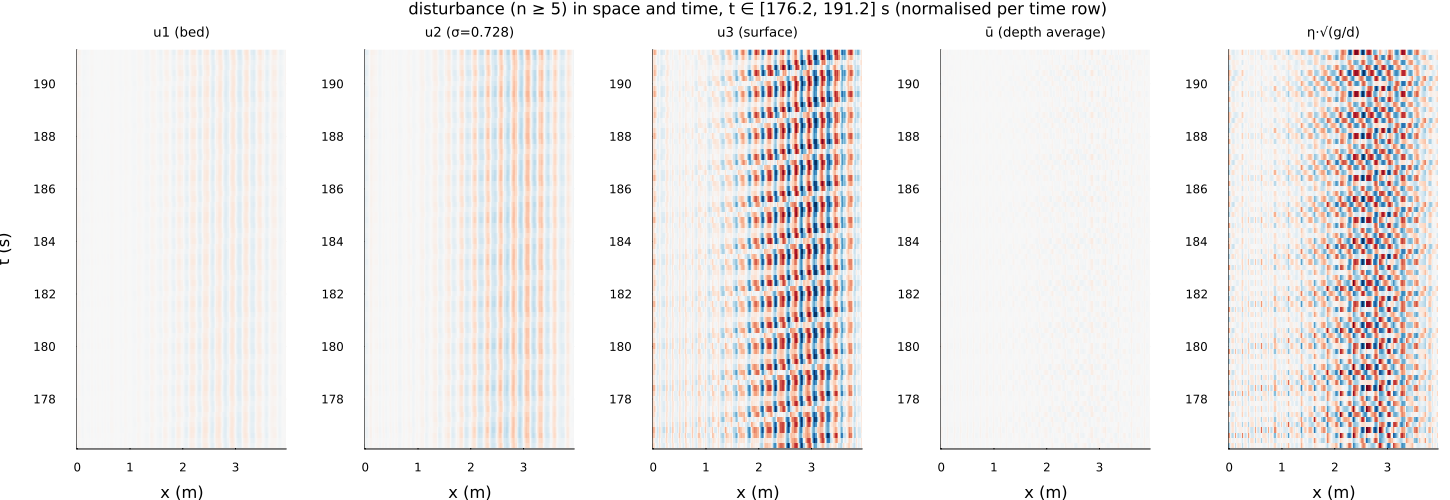

In [18]:
f = plot_layers_hovmoller(R; tw = (T_LIN - 15, T_LIN), nmin = NMIN); savefig(f, joinpath(OUTDIR, "12_hovmoller_layers.png")); showpng(f)

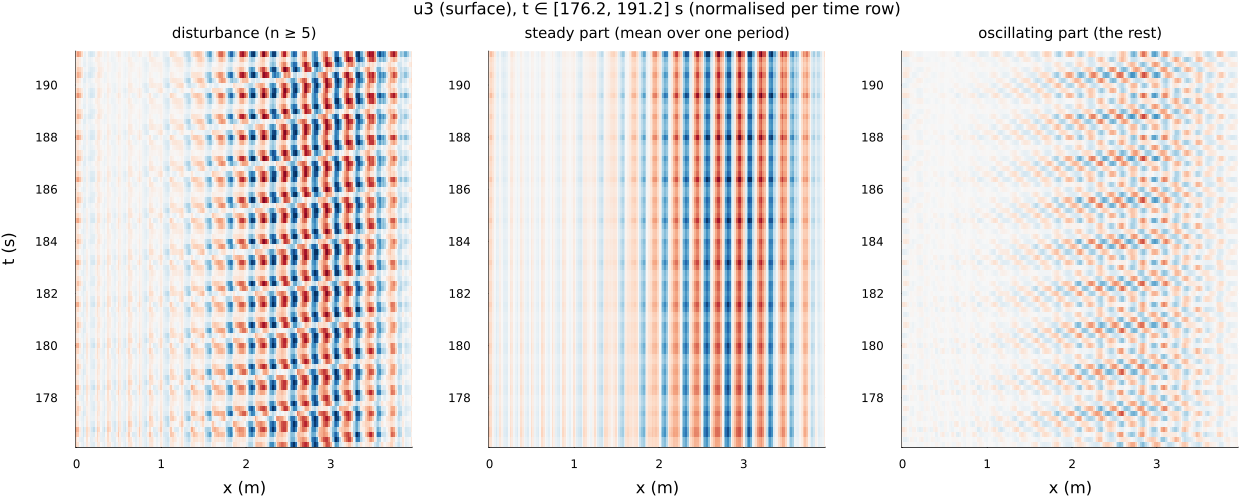

In [19]:
f = plot_steady_split(R; tw = (T_LIN - 15, T_LIN), nmin = NMIN); savefig(f, joinpath(OUTDIR, "13_steady_split.png")); showpng(f)

## 10. Energy: where it is, and where it goes

The energy of the linearised layered model, per unit area, for every harmonic, split in four:

* **surface** g η²/2;
* **depth-mean kinetic** d ū²/2: the net flow;
* **vertical-shear kinetic** d (uᵀA u − ū²)/2: what the depth average misses (A = ∫φᵢφⱼ dσ);
* **vertical kinetic** d³ (∂ₓu)ᵀB(∂ₓu)/2: the energy of the vertical velocity w (B = ∫Φᵢ Φⱼ dσ). This is the term that
  makes the model dispersive: its frequency is ω² = g d k² Dᵀ(A + k²d²B)⁻¹D.

Panel (a) compares totals. The **solver's monitor** (`energy_ratio` in `diagnostics.csv`, the `E1.007` in the logs)
is g η²/2 + H uᵀM u/2: it **leaves out the vertical kinetic energy**. The snapshots without w reproduce the monitor to
0.1 %, which checks the decomposition. With w included the early fluctuation is about half as large (0.5 % instead of
0.9 % over 5–180 s), so that is the energy this model conserves. And the w-energy is where the disturbance lives
(panels c, d: about 97 % of it), because short waves have large ∂ₓu. **So the full energy rises from ≈ 185 s, while
the monitor stays at 1.00 until the final blow-up: the monitor is nearly blind to this instability.**

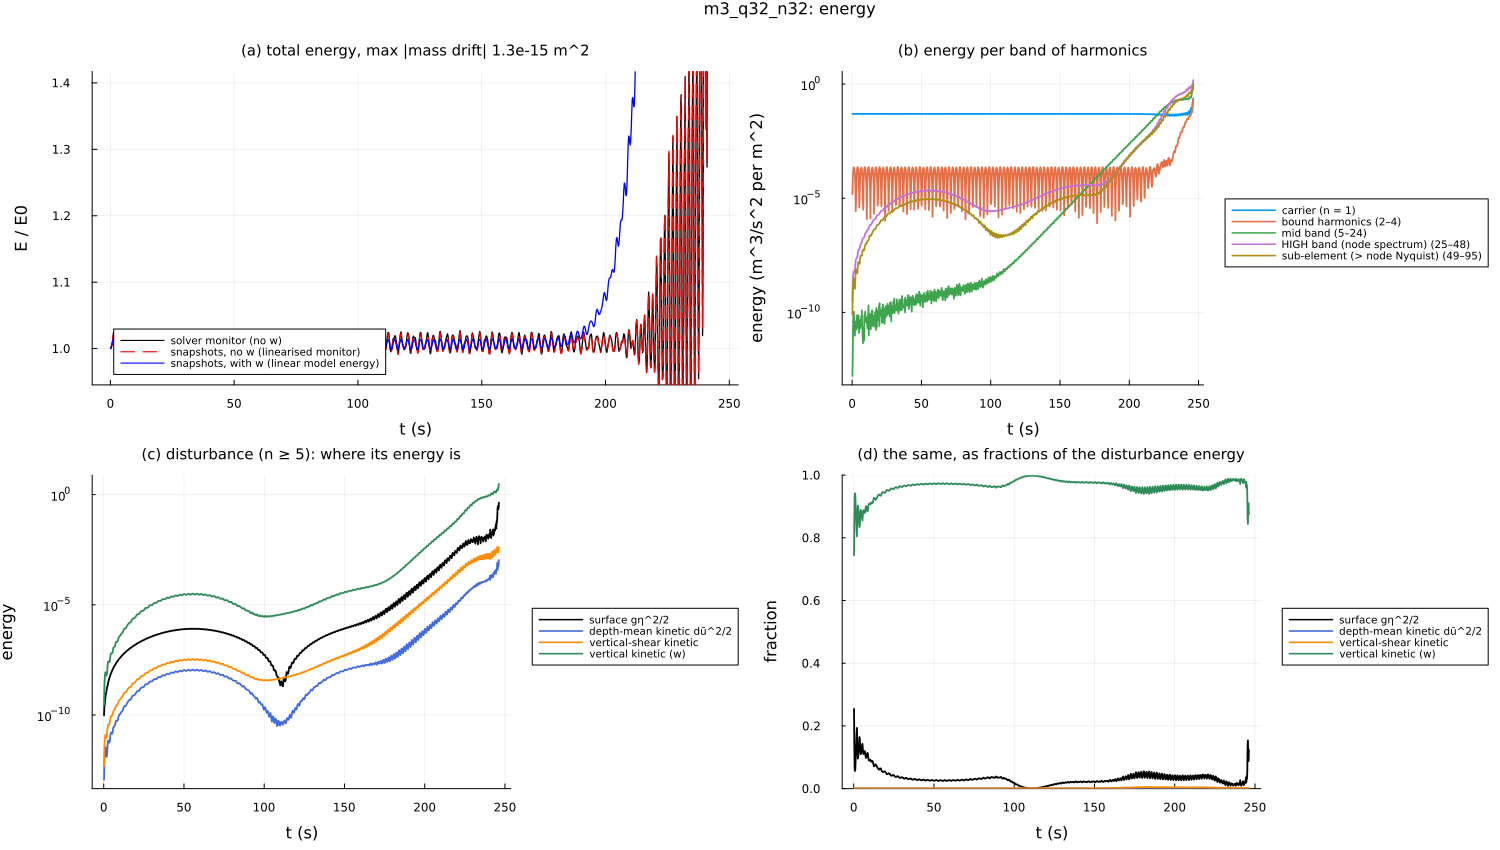

In [20]:
f = plot_energy(R; nmin = NMIN); savefig(f, joinpath(OUTDIR, "02_energy.png")); showpng(f)

### Energy over time, mode by mode

`plot_energy_history` follows the energy of each mode through the run (log scale; surface + depth-mean + shear + w,
from the nodal modes, so each mode appears once). `modes` chooses what is drawn:

* `:groups`: the total, the carrier, the bound harmonics, the disturbance and n = 0 (the x-uniform flow);
  with `relative = true` everything is divided by the total at t = 0;
* `:all`: one line per mode, coloured by n (n = 0 red dashed);
* a list, e.g. `[1, 2, 14, 16, 32, 48]`.

By default each curve is averaged over one wave period (`avg = :period`): a free wave swaps its energy between the
surface and the velocity twice per period. The slow wiggle left on the bound harmonics is real: it is the beat
between the bound and the free second harmonic. **A straight rising line on this log scale is exponential growth;**
its slope is twice the amplitude growth rate.

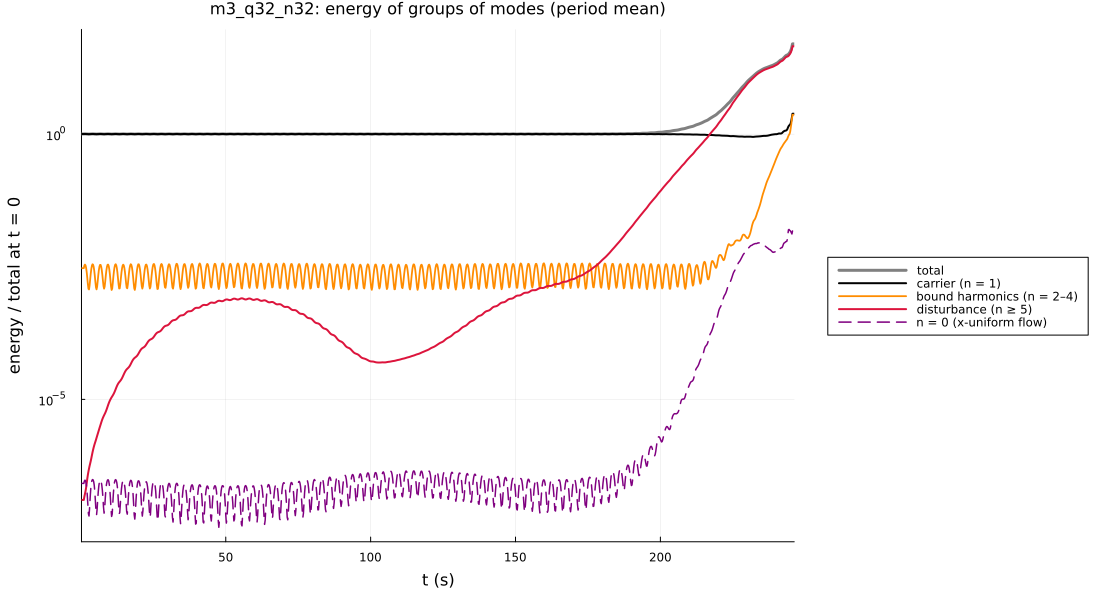

In [21]:
f = plot_energy_history(R; modes = :groups, relative = true, nmin = NMIN); savefig(f, joinpath(OUTDIR, "15_energy_history_groups.png")); showpng(f)

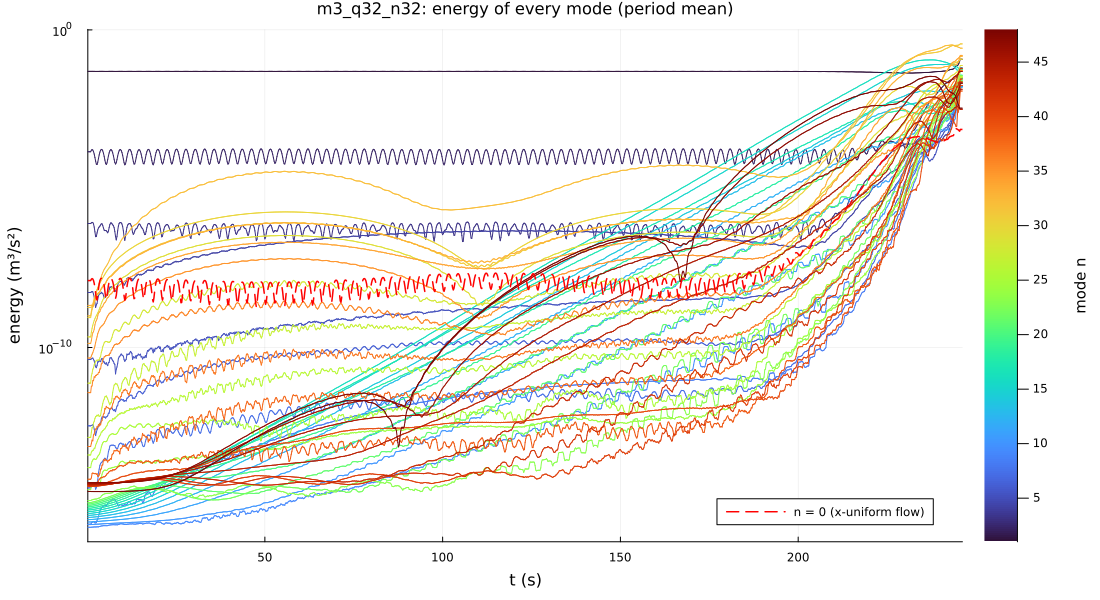

In [22]:
f = plot_energy_history(R; modes = :all); savefig(f, joinpath(OUTDIR, "16_energy_history_modes.png")); showpng(f)

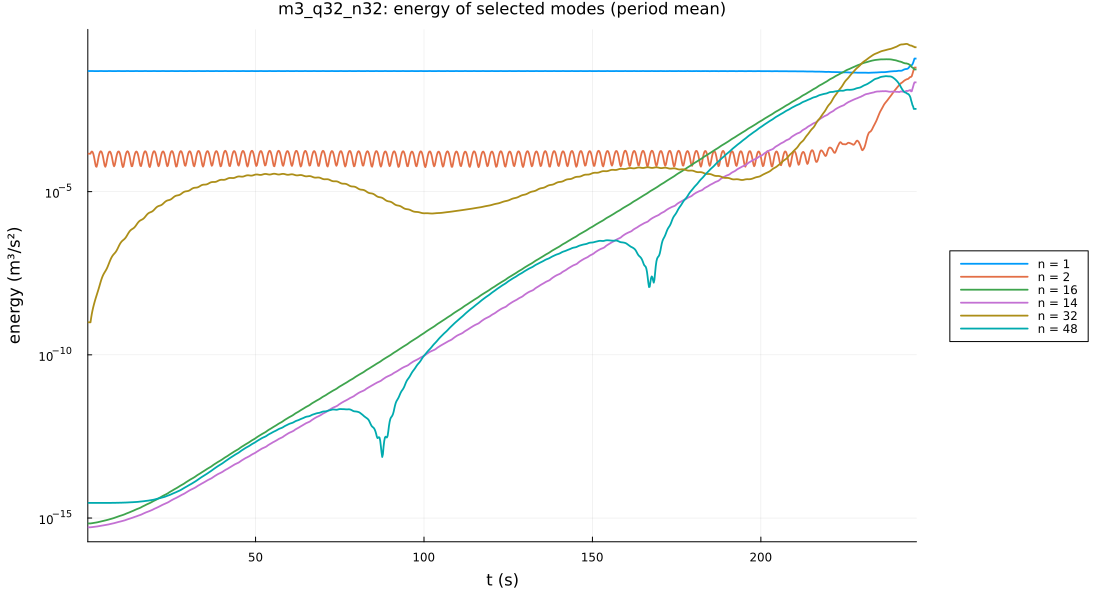

In [23]:
f = plot_energy_history(R; modes = unique([HARM; 48])); savefig(f, joinpath(OUTDIR, "17_energy_history_selected.png")); showpng(f)

**The energy spectrum**: energy per harmonic at several times (left): the disturbance fills the spectrum in humps
(the triad band around n ≈ 15 grows first), and (right) the composition of each harmonic at the last snapshot.

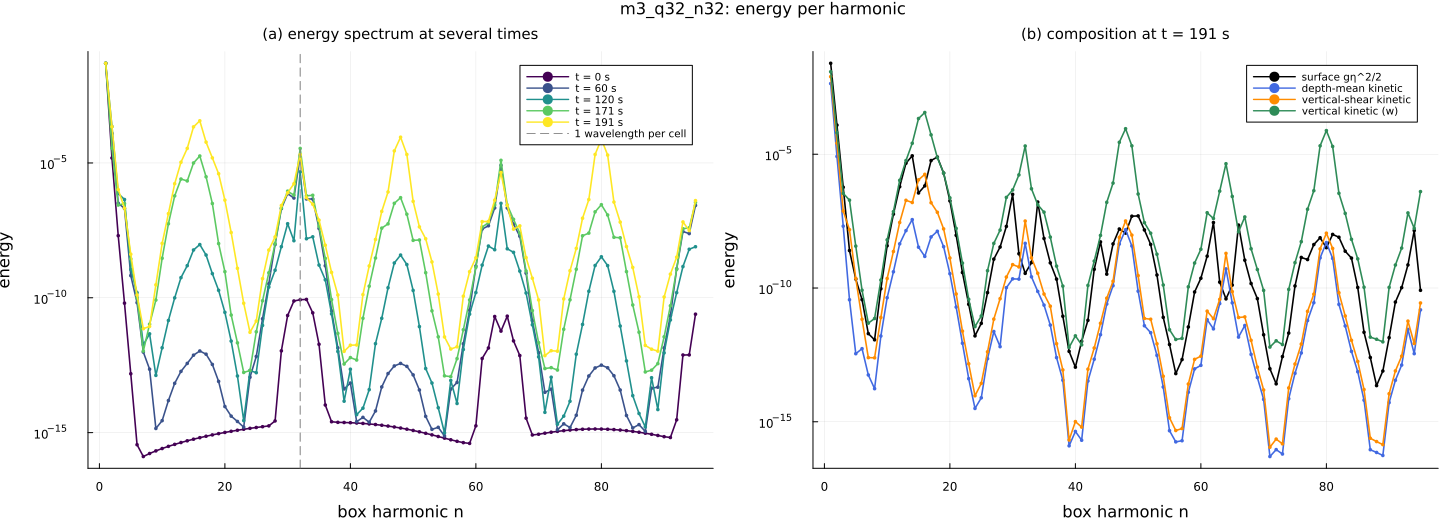

In [24]:
f = plot_energy_spectrum(R; times = [0, 60, 120, T_LIN - 20, T_LIN]); savefig(f, joinpath(OUTDIR, "03_energy_spectrum.png")); showpng(f)

## 11. The triad: why these two grow together

Where the energy of the surface-layer velocity sits in **wavenumber (n, horizontal)** and **frequency (ω, vertical)**,
over the growth window. The white dashed curve is the model's surface-wave branch: free surface waves can only live
on it, and at short wavelengths it flattens out at ω∞ ≈ 2ω0. The red line ω = 0 is where steady patterns sit.

A **decay triad** is three waves that exchange energy because their wavenumbers and frequencies add up:

  pump (n = 2, ω = 2ω0)  =  steady (n = n_s, ω = 0)  +  fast (n = 2 − n_s, ω = 2ω0).

The carrier's second harmonic (the pump) is always there. Because the branch saturates at ω∞ ≈ 2ω0 *exactly* at
T = 1.6 s, a short backward wave with ω = 2ω0 exists, and the steady pattern costs no frequency at all. So the pump
can feed both at once, and they grow together at the same rate. The three circles mark the members.

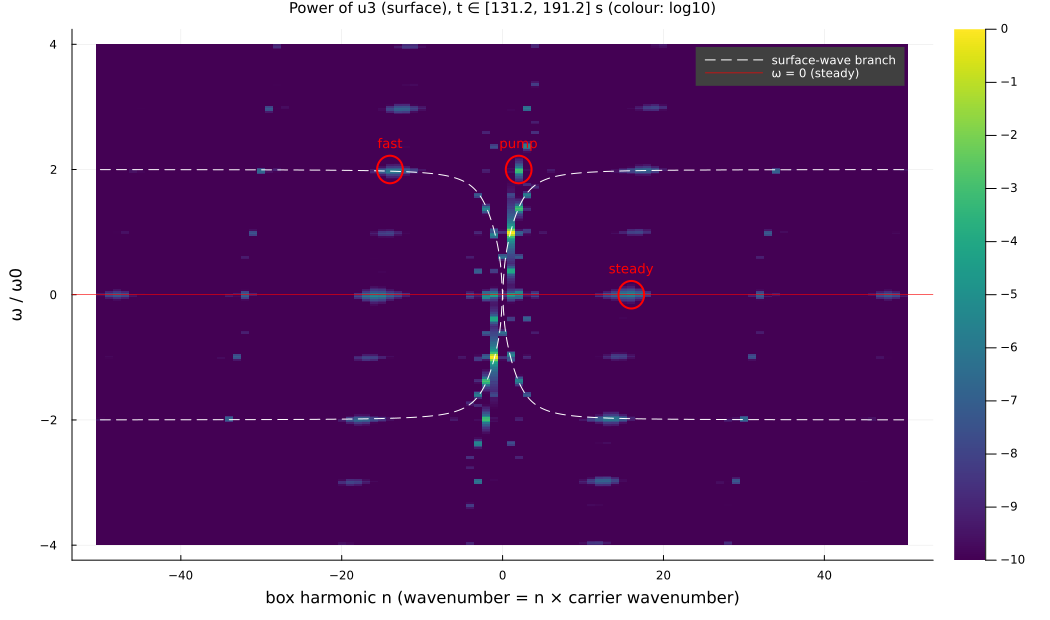

In [25]:
marks = isnothing(TRIAD) ? [] : [(2, 2.0, "pump"), (TRIAD[1], 0.0, "steady"), (-TRIAD[2], 2.0, "fast")]
f = plot_komega(R; tw = TW, marks = marks); savefig(f, joinpath(OUTDIR, "14_k_omega.png")); showpng(f)

## 12. Does this show how the instability really progresses?

Yes, with these limits:

* **These are the actual discrete solutions**, read from the run's VTK files: nothing is simulated here. The only
  choices are the split carrier / disturbance (n ≥ 5) and the period mean used for "steady".
* **Sampling: one snapshot every 0.2 s** (T/8 at T = 1.6 s). Anything oscillating faster than 4ω0 is folded back
  (aliased); in particular **8ω0 would look exactly steady**. Surface waves of this model cannot exceed ω∞ ≈ 2ω0, so
  nothing physical lives there, but a strongly Doppler-shifted content could. The flat lines in §7 change smoothly
  over 30–40 samples, so they are not an alias of a fast oscillation.
* **w, the streamlines and the vertical kinetic energy are linearised reconstructions** (flat bed, H → d). The
  velocities u_j and η themselves are exact.
* The normalised maps hide the absolute size on purpose: always read them with the growth curves next to them.